In [3]:
import sqlite3, os
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../docs/img", exist_ok=True)
con = sqlite3.connect("../data/chilecompra.db")

plt.rcParams.update({
    "figure.figsize": (9, 5), "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 11,
})
AZUL, GRIS, NARANJA = "#1f4e79", "#b0b7bf", "#e07b39"

FILTRO = "EsMontoValido = 1 AND EsDatoInvalido = 0"
print("Conectado. Filas en la tabla:", pd.read_sql("SELECT COUNT(*) n FROM ordenes_items", con)["n"][0])

Conectado. Filas en la tabla: 363914


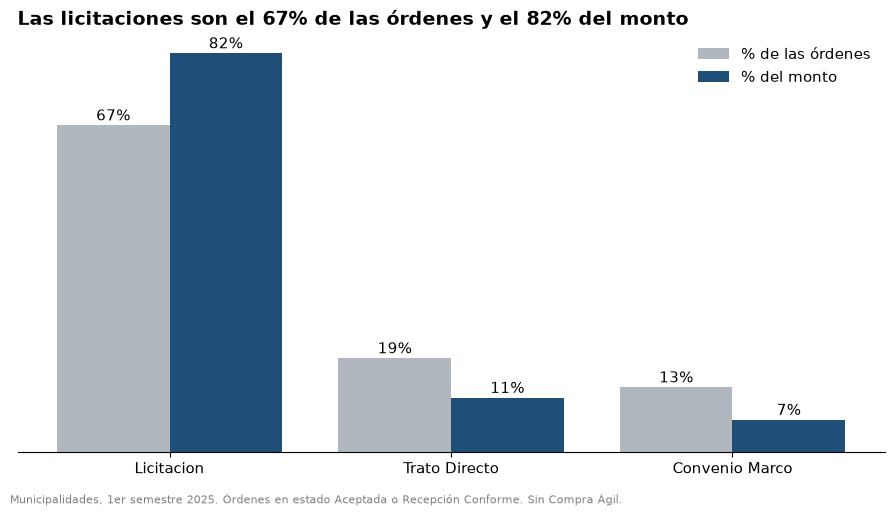

In [2]:
q = f"""
SELECT Modalidad, COUNT(DISTINCT codigoOC) AS ordenes, SUM(MontoNetoItemCLP) AS monto
FROM ordenes_items WHERE {FILTRO} GROUP BY Modalidad
"""
d = pd.read_sql(q, con)
d["pct_ordenes"] = 100 * d["ordenes"] / d["ordenes"].sum()
d["pct_monto"] = 100 * d["monto"] / d["monto"].sum()
d = d.sort_values("pct_monto", ascending=False)

lic = d[d["Modalidad"] == "Licitacion"].iloc[0]
fig, ax = plt.subplots()
x = range(len(d))
ax.bar([i - 0.2 for i in x], d["pct_ordenes"], 0.4, label="% de las órdenes", color=GRIS)
ax.bar([i + 0.2 for i in x], d["pct_monto"], 0.4, label="% del monto", color=AZUL)
for i, (po, pm) in enumerate(zip(d["pct_ordenes"], d["pct_monto"])):
    ax.text(i - 0.2, po + 1, f"{po:.0f}%", ha="center")
    ax.text(i + 0.2, pm + 1, f"{pm:.0f}%", ha="center")
ax.set_xticks(list(x)); ax.set_xticklabels(d["Modalidad"])
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"Las licitaciones son el {lic.pct_ordenes:.0f}% de las órdenes y el {lic.pct_monto:.0f}% del monto")
fig.text(0.01, -0.02, "Municipalidades, 1er semestre 2025. Órdenes en estado Aceptada o Recepción Conforme. Sin Compra Ágil.",
         fontsize=8, color="gray")
plt.tight_layout(); plt.savefig("../docs/img/01_modalidades.png", dpi=150, bbox_inches="tight"); plt.show()

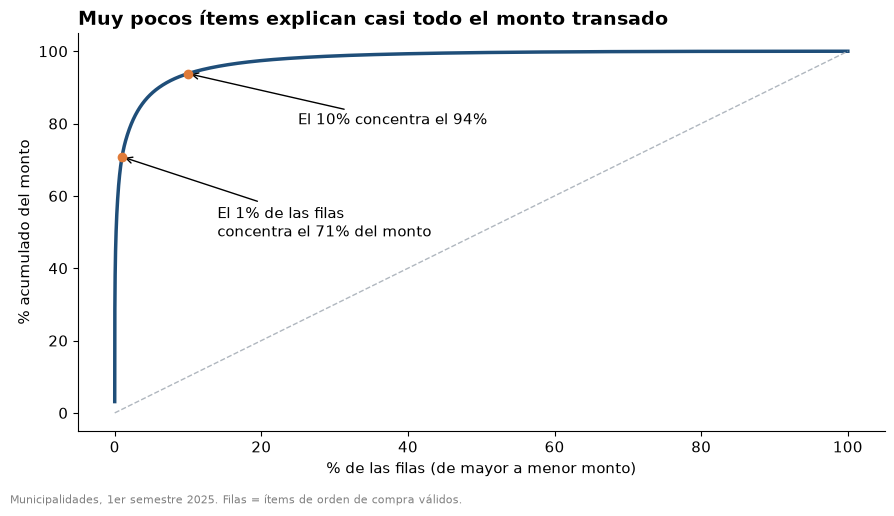

In [3]:
m = pd.read_sql(f"SELECT MontoNetoItemCLP AS monto FROM ordenes_items WHERE {FILTRO} AND MontoNetoItemCLP IS NOT NULL", con)["monto"]
m = m.sort_values(ascending=False).reset_index(drop=True)
x = (m.index + 1) / len(m) * 100
y = m.cumsum() / m.sum() * 100

p1 = y[int(len(m) * 0.01) - 1]
p10 = y[int(len(m) * 0.10) - 1]
fig, ax = plt.subplots()
ax.plot(x, y, color=AZUL, lw=2.5)
ax.plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1)
ax.scatter([1, 10], [p1, p10], color=NARANJA, zorder=5)
ax.annotate(f"El 1% de las filas\nconcentra el {p1:.0f}% del monto", (1, p1), xytext=(14, p1 - 22), arrowprops=dict(arrowstyle="->"))
ax.annotate(f"El 10% concentra el {p10:.0f}%", (10, p10), xytext=(25, p10 - 14), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("% de las filas (de mayor a menor monto)"); ax.set_ylabel("% acumulado del monto")
ax.set_title("Muy pocos ítems explican casi todo el monto transado")
fig.text(0.01, -0.02, "Municipalidades, 1er semestre 2025. Filas = ítems de orden de compra válidos.", fontsize=8, color="gray")
plt.tight_layout(); plt.savefig("../docs/img/02_concentracion.png", dpi=150, bbox_inches="tight"); plt.show()

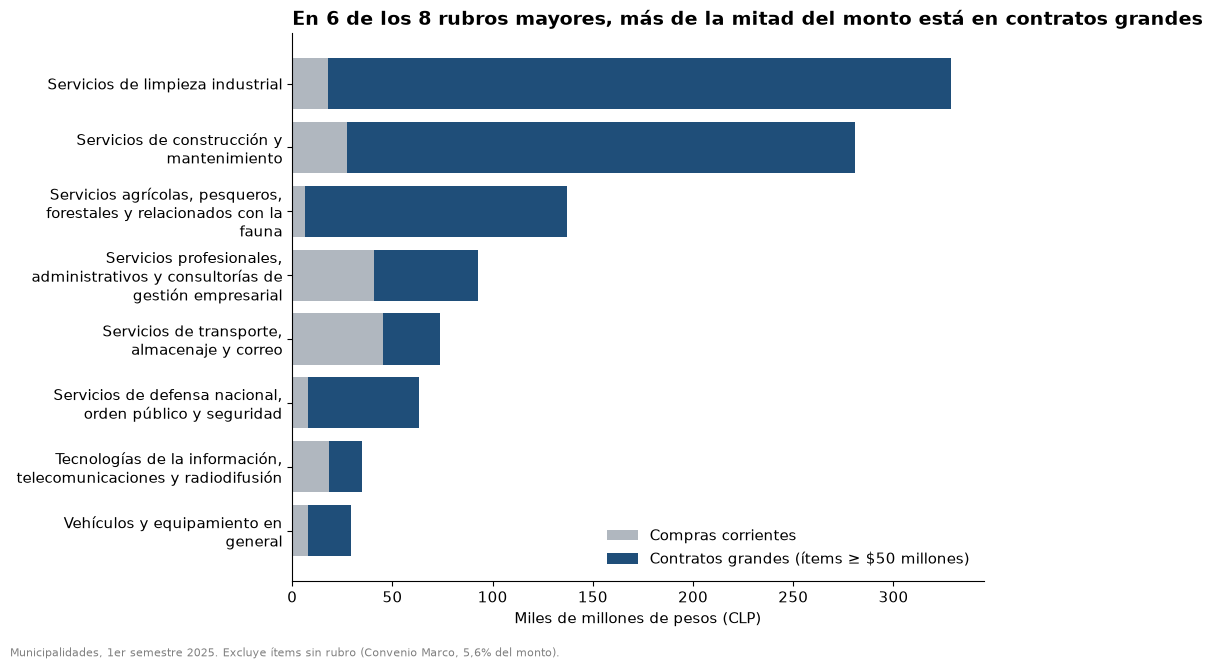

In [4]:
import re, textwrap

q = f"""
SELECT RubroN1 AS rubro,
       SUM(CASE WHEN EsContratoGrande = 0 THEN MontoNetoItemCLP ELSE 0 END) / 1e9 AS corriente,
       SUM(CASE WHEN EsContratoGrande = 1 THEN MontoNetoItemCLP ELSE 0 END) / 1e9 AS grande
FROM ordenes_items
WHERE {FILTRO} AND RubroN1 IS NOT NULL AND TRIM(RubroN1) <> ''
GROUP BY RubroN1
ORDER BY SUM(MontoNetoItemCLP) DESC
LIMIT 8
"""
d = pd.read_sql(q, con)
n_mayoria = int((d["grande"] > d["corriente"]).sum())
d = d.iloc[::-1]  # el mayor queda arriba
etiquetas = [textwrap.fill(r, 34) for r in d["rubro"]]

fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(etiquetas, d["corriente"], color=GRIS, label="Compras corrientes")
ax.barh(etiquetas, d["grande"], left=d["corriente"], color=AZUL, label="Contratos grandes (ítems ≥ $50 millones)")
ax.set_xlabel("Miles de millones de pesos (CLP)")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"En {n_mayoria} de los 8 rubros mayores, más de la mitad del monto está en contratos grandes")
fig.text(0.01, -0.02, "Municipalidades, 1er semestre 2025. Excluye ítems sin rubro (Convenio Marco, 5,6% del monto).",
         fontsize=8, color="gray")
plt.tight_layout(); plt.savefig("../docs/img/03_rubros.png", dpi=150, bbox_inches="tight"); plt.show()

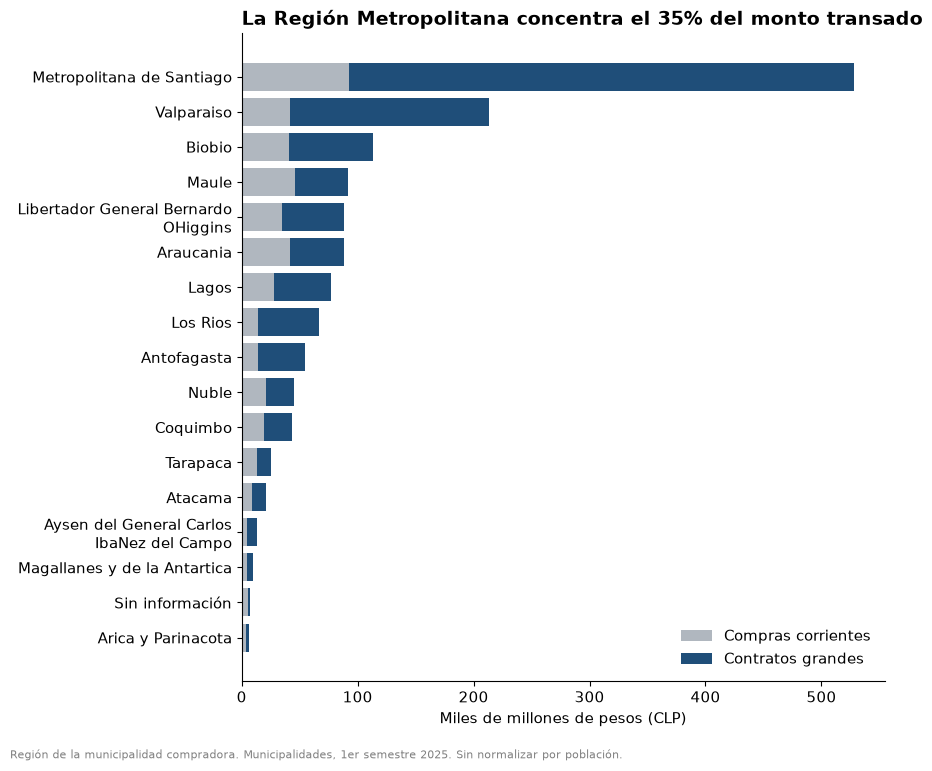

In [5]:
q = f"""
SELECT RegionUnidadCompra AS region,
       SUM(CASE WHEN EsContratoGrande = 0 THEN MontoNetoItemCLP ELSE 0 END) / 1e9 AS corriente,
       SUM(CASE WHEN EsContratoGrande = 1 THEN MontoNetoItemCLP ELSE 0 END) / 1e9 AS grande
FROM ordenes_items
WHERE {FILTRO}
GROUP BY RegionUnidadCompra
ORDER BY SUM(MontoNetoItemCLP) DESC
"""
d = pd.read_sql(q, con)
d["total"] = d["corriente"] + d["grande"]
pct_rm = 100 * d.loc[d["region"].str.contains("Metropolitana"), "total"].iloc[0] / d["total"].sum()
d["region"] = [re.sub(r"^Region (de los |de las |de la |del |de )?", "", r) for r in d["region"]]
d = d.iloc[::-1]
etiquetas = [textwrap.fill(r, 30) for r in d["region"]]

fig, ax = plt.subplots(figsize=(9, 7.5))
ax.barh(etiquetas, d["corriente"], color=GRIS, label="Compras corrientes")
ax.barh(etiquetas, d["grande"], left=d["corriente"], color=AZUL, label="Contratos grandes")
ax.set_xlabel("Miles de millones de pesos (CLP)")
ax.legend(frameon=False, loc="lower right")
ax.set_title(f"La Región Metropolitana concentra el {pct_rm:.0f}% del monto transado")
fig.text(0.01, -0.02, "Región de la municipalidad compradora. Municipalidades, 1er semestre 2025. Sin normalizar por población.",
         fontsize=8, color="gray")
plt.tight_layout(); plt.savefig("../docs/img/04_regiones.png", dpi=150, bbox_inches="tight"); plt.show()

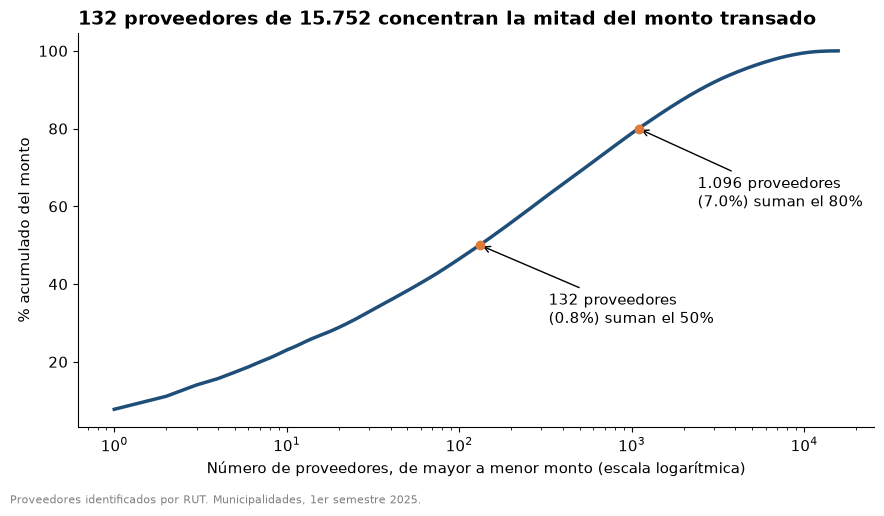

In [4]:
p = pd.read_sql(f"""
SELECT SUM(MontoNetoItemCLP) AS monto FROM ordenes_items
WHERE {FILTRO} AND ProveedorRUT IS NOT NULL AND MontoNetoItemCLP IS NOT NULL
GROUP BY UPPER(TRIM(ProveedorRUT))
""", con)["monto"].sort_values(ascending=False).reset_index(drop=True)

y = p.cumsum() / p.sum() * 100
x = p.index + 1
n50 = int((y >= 50).idxmax()) + 1
n80 = int((y >= 80).idxmax()) + 1

fig, ax = plt.subplots()
ax.plot(x, y, color=AZUL, lw=2.5)
ax.set_xscale("log")
ax.scatter([n50, n80], [50, 80], color=NARANJA, zorder=5)
ax.annotate(f"{n50:,} proveedores\n({100 * n50 / len(p):.1f}%) suman el 50%".replace(",", "."), (n50, 50),
            xytext=(n50 * 2.5, 30), arrowprops=dict(arrowstyle="->"))
ax.annotate(f"{n80:,} proveedores\n({100 * n80 / len(p):.1f}%) suman el 80%".replace(",", "."), (n80, 80),
            xytext=(n80 * 2.2, 60), arrowprops=dict(arrowstyle="->"))
ax.set_xlabel("Número de proveedores, de mayor a menor monto (escala logarítmica)")
ax.set_ylabel("% acumulado del monto")
ax.set_title(f"{n50} proveedores de {len(p):,}".replace(",", ".") + " concentran la mitad del monto transado")
fig.text(0.01, -0.02, "Proveedores identificados por RUT. Municipalidades, 1er semestre 2025.", fontsize=8, color="gray")
plt.tight_layout(); plt.savefig("../docs/img/05_proveedores.png", dpi=150, bbox_inches="tight"); plt.show()

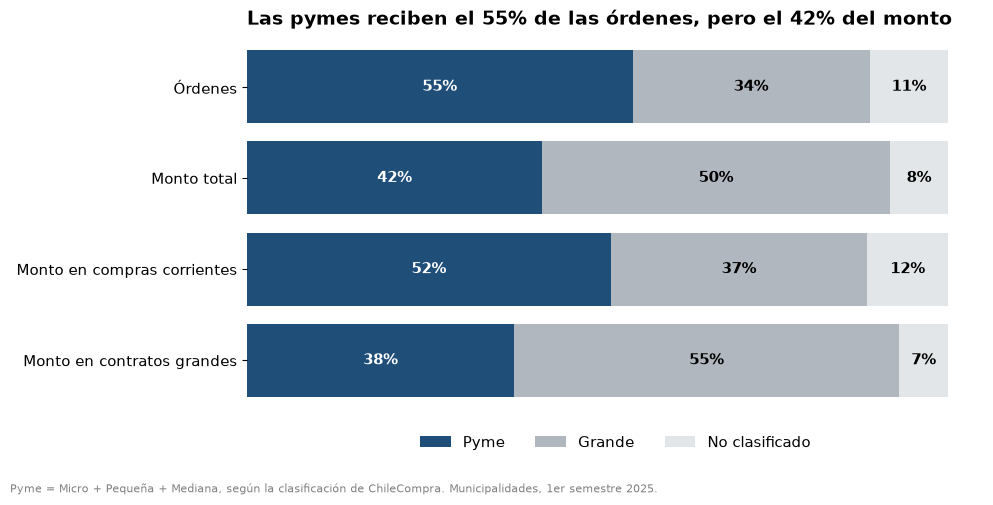

In [7]:
q = f"""
SELECT CASE WHEN TamanoProveedor IN ('Micro','Pequeña','Mediana') THEN 'Pyme'
            WHEN TamanoProveedor = 'Grande' THEN 'Grande'
            ELSE 'No clasificado' END AS grupo,
       COUNT(DISTINCT codigoOC) AS ordenes,
       SUM(MontoNetoItemCLP) AS monto,
       SUM(CASE WHEN EsContratoGrande = 0 THEN MontoNetoItemCLP ELSE 0 END) AS corr,
       SUM(CASE WHEN EsContratoGrande = 1 THEN MontoNetoItemCLP ELSE 0 END) AS grande
FROM ordenes_items WHERE {FILTRO} GROUP BY grupo
"""
g = pd.read_sql(q, con).set_index("grupo")
cols = {"Órdenes": "ordenes", "Monto total": "monto",
        "Monto en compras corrientes": "corr", "Monto en contratos grandes": "grande"}
pct = g[list(cols.values())] / g[list(cols.values())].sum() * 100

fig, ax = plt.subplots(figsize=(10, 4.8))
left = [0.0] * len(cols)
for grupo, color, txt in [("Pyme", AZUL, "white"), ("Grande", GRIS, "black"), ("No clasificado", "#e3e6e9", "black")]:
    vals = pct.loc[grupo, list(cols.values())].values
    ax.barh(list(cols.keys()), vals, left=left, color=color, label=grupo)
    for i, v in enumerate(vals):
        if v > 4:
            ax.text(left[i] + v / 2, i, f"{v:.0f}%", ha="center", va="center", color=txt, fontweight="bold")
    left = [l + v for l, v in zip(left, vals)]
ax.invert_yaxis(); ax.set_xticks([])
ax.spines["bottom"].set_visible(False); ax.spines["left"].set_visible(False)
ax.legend(frameon=False, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.02))
ax.set_title(f"Las pymes reciben el {pct.loc['Pyme', 'ordenes']:.0f}% de las órdenes, pero el {pct.loc['Pyme', 'monto']:.0f}% del monto")
fig.text(0.01, -0.04, "Pyme = Micro + Pequeña + Mediana, según la clasificación de ChileCompra. Municipalidades, 1er semestre 2025.",
         fontsize=8, color="gray")
plt.tight_layout(); plt.savefig("../docs/img/06_pymes.png", dpi=150, bbox_inches="tight"); plt.show()

In [8]:
cols = ["codigoOC", "Fecha", "Mes", "Modalidad", "Institucion", "RegionUnidadCompra",
        "Proveedor", "ProveedorRUT", "TamanoProveedor", "RubroN1", "RubroN2",
        "MontoNetoItemCLP", "EsContratoGrande"]
d = pd.read_sql(f"SELECT {', '.join(cols)} FROM ordenes_items "
                f"WHERE {FILTRO} AND MontoNetoItemCLP IS NOT NULL", con)

d["MontoNetoItemCLP"] = d["MontoNetoItemCLP"].round(0).astype("int64")
d["RubroN1"] = d["RubroN1"].replace("", None).fillna("Sin rubro (Convenio Marco)")
d.to_csv("../data/processed/ordenes_powerbi.csv", index=False, encoding="utf-8-sig")
print(len(d), "filas exportadas")

353844 filas exportadas
